In [28]:
import sys
sys.path.append("./src")

import os

In [29]:
import warnings
warnings.filterwarnings("ignore")

In [30]:
from prosit.simulator import SimulatorParameters, SimulatorEngine

import pm4py
from pm4py.objects.log.importer.xes import importer as xes_importer
import pandas as pd

In [31]:
# import event log and Petri net model
# os.chdir('/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/prosit-recommendations-simulator')
log = xes_importer.apply("../bpi12a.xes")
net, im, fm = pm4py.discover_petri_net_inductive(log, noise_threshold=0.1)

parsing log, completed traces ::   0%|          | 0/13087 [00:00<?, ?it/s]

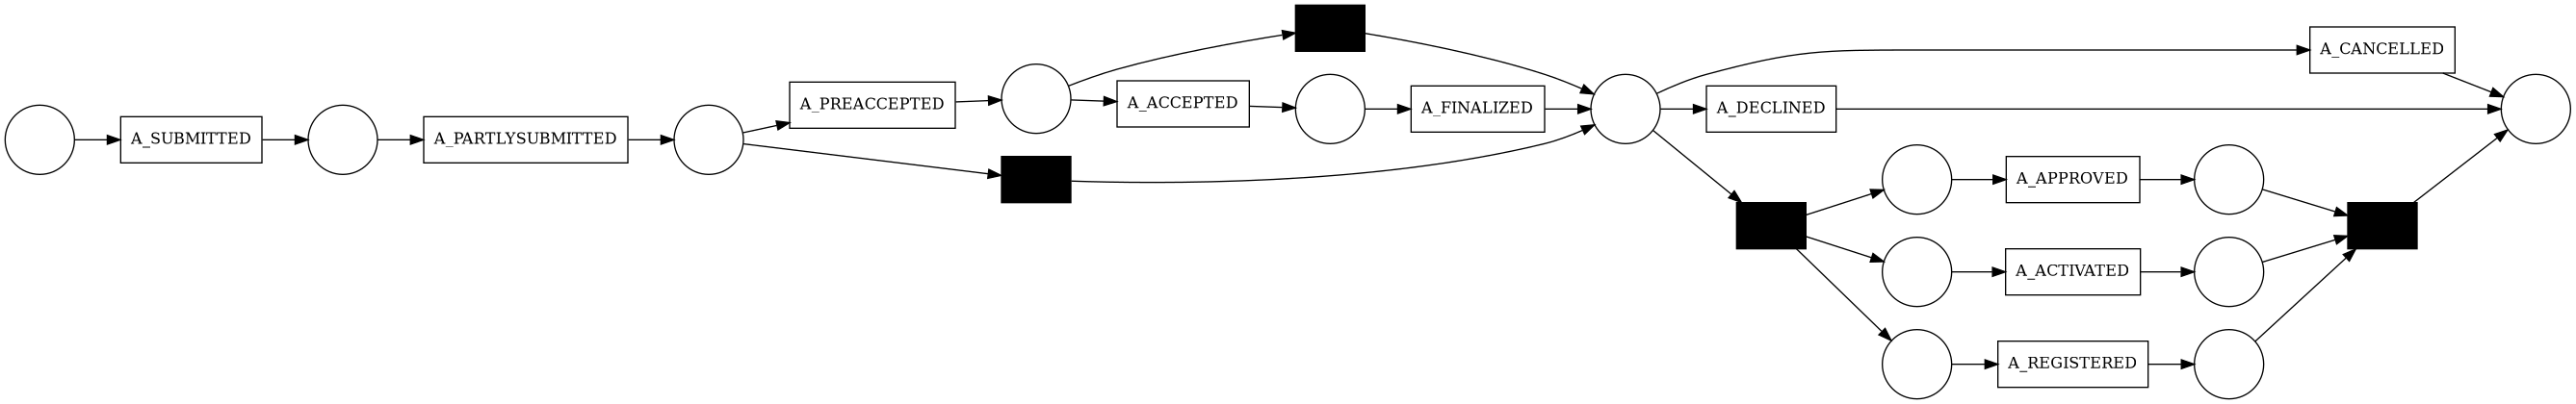

In [32]:
pm4py.view_petri_net(net)

In [33]:
pm4py.fitness_alignments(log, net, im, fm)

aligning log, completed variants ::   0%|          | 0/17 [00:00<?, ?it/s]

{'percFitTraces': 96.22526171009399,
 'averageFitness': 0.995025052123703,
 'percentage_of_fitting_traces': 96.22526171009399,
 'average_trace_fitness': 0.995025052123703,
 'log_fitness': 0.9950230737519067}

In [34]:
pm4py.precision_alignments(log, net, im, fm)

computing precision with alignments, completed variants ::   0%|          | 0/14 [00:00<?, ?it/s]

0.667223516096032

In [35]:
# function for creating a recommendation DataFrame to use for simulation

def build_recommender_df(prev_log: pd.DataFrame, recommendations: dict) -> pd.DataFrame:

    prev_log["recommendation:act"] = None
    prev_log["recommendation:res"] = None 

    for case_id, recs in recommendations.items():
        act = recs.get("act", None)
        res = recs.get("res", None)
        last_index = prev_log[prev_log['case:concept:name'] == case_id].index[-1]
        prev_log.at[last_index, "recommendation:act"] = act
        prev_log.at[last_index, "recommendation:res"] = res
        
    return prev_log

In [36]:
# Create a random log with previous event (for test)
df_log = pm4py.convert_to_dataframe(log)

prev_log = pd.read_csv("/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/experiments/bpi12_kappel/running_log.csv", index_col=0)
prev_log = prev_log[df_log.columns]

In [37]:
prev_log['case:concept:name'] = prev_log['case:concept:name'].astype(str)
prev_log['time:timestamp'] = pd.to_datetime(prev_log['time:timestamp'], format="mixed")
prev_log['start:timestamp'] = pd.to_datetime(prev_log['start:timestamp'], format="mixed")

In [38]:
# # create a recommendation dictionary
# # recommend activity "Amend Request for Quotation Requester Manager" and resource "Penn Osterwalder" for case "6"

# recommendations = {
#     "6": {
#         "act": "Amend Request for Quotation Requester Manager", 
#         "res": "Penn Osterwalder"
#         }
#     }

# # build recommendation dataframe
# log_rec = build_recommender_df(prev_log, recommendations)

In [39]:
def compute_activity_resource_probabilities(
    event_log,
    activity_col='concept:name',
    resource_col='org:resource'):
    """
    Compute resource probability distributions per activity.

    Returns
    -------
    dict
        Mapping:
        {
            <activity>: [(<resource_1>, <prob_1>), (<resource_2>, <prob_2>), ...]
        }
    """
    if activity_col not in event_log.columns:
        raise ValueError(f"Column '{activity_col}' not found in event_log.")
    if resource_col not in event_log.columns:
        raise ValueError(f"Column '{resource_col}' not found in event_log.")

    df = event_log[[activity_col, resource_col]].dropna()
    if df.empty:
        return {}

    # Frequency table and normalized probabilities per activity.
    counts = (
        df.groupby([activity_col, resource_col])
        .size()
        .rename('count')
        .reset_index()
    )
    counts['probability'] = counts.groupby(activity_col)['count'].transform(
        lambda x: x / x.sum()
    )

    distributions = {}
    for activity, group in counts.groupby(activity_col):
        group_sorted = group.sort_values('probability', ascending=False)
        distributions[activity] = [
            (row[resource_col], float(row['probability']))
            for _, row in group_sorted.iterrows()
        ]

    return distributions

In [40]:
# for rec_file in rec_files:

rec_df = pd.read_csv('/home/padela/Scrivania/Fair-PrescriptiveProcessMonitoring/experiments/bpi12_kappel/LSTM_recommended_activities.csv')
resources_prob = compute_activity_resource_probabilities(df_log)
# Build input recommendations dict from case/activity columns
recommendations = {}
prev_log2 = prev_log.copy()

print(prev_log2.columns)

# prev_log['case:REG_DATE'] = prev_log['case:REG_DATE'].astype(int)
prev_log2['case:AMOUNT_REQ'] = prev_log2['case:AMOUNT_REQ'].astype(int)


prev_log2["case:concept:name"] = prev_log2["case:concept:name"].astype(str)
valid_cases = set(prev_log2["case:concept:name"].unique())

for _, row in rec_df.iterrows():
    raw_case_id = row.get("case:concept:name", row.get("case_id"))
    raw_act = row.get("concept:name", row.get("activity"))

    if pd.isna(raw_case_id) or pd.isna(raw_act):
        continue

    case_id = str(raw_case_id)
    if case_id not in valid_cases:
        continue

    # Assign the most probable resource for the recommended activity
    resource_distribution = resources_prob.get(raw_act, [])
    if resource_distribution:
        most_probable_resource = resource_distribution[0][0]
    else:
        
        most_probable_resource = None
    
    # recommendations[case_id] = {"act": raw_act, "res": str(most_probable_resource)}
    recommendations[case_id] = {"act": raw_act, "res": None}


Index(['concept:name', 'org:resource', 'time:timestamp', 'start:timestamp',
       'case:concept:name', 'case:AMOUNT_REQ'],
      dtype='object')


In [41]:
# build recommendation dataframe
log_rec = build_recommender_df(prev_log, recommendations)

In [42]:
log_rec

,concept:name,org:resource,time:timestamp,start:timestamp,case:concept:name,case:AMOUNT_REQ,recommendation:act,recommendation:res
0,A_SUBMITTED,112,2012-02-03 17:23:41.949000+00:00,2012-02-03 17:23:41.949000+00:00,206327,6000,None,None
1,A_PARTLYSUBMITTED,112,2012-02-03 17:23:42.504000+00:00,2012-02-03 17:23:41.949000+00:00,206327,6000,A_DECLINED,None
2,A_SUBMITTED,112,2012-02-03 17:24:30.409000+00:00,2012-02-03 17:24:30.409000+00:00,206330,2500,None,None
3,A_PARTLYSUBMITTED,112,2012-02-03 17:24:30.620000+00:00,2012-02-03 17:24:30.409000+00:00,206330,2500,A_DECLINED,None
4,A_SUBMITTED,112,2012-02-03 17:43:51.563000+00:00,2012-02-03 17:43:51.563000+00:00,206333,15000,None,None
...,...,...,...,...,...,...,...,...
7161,A_SUBMITTED,112,2012-02-29 23:43:09.766000+00:00,2012-02-29 23:43:09.766000+00:00,214373,8500,None,None
7162,A_PARTLYSUBMITTED,112,2012-02-29 23:43:09.899000+00:00,2012-02-29 23:43:09.766000+00:00,214373,8500,None,None
7163,A_PREACCEPTED,11169,2012-03-01 09:27:50.503000+00:00,2012-02-29 23:43:09.899000+00:00,214373,8500,A_CANCELLED,None
7164,A_SUBMITTED,112,2012-02-29 23:51:16.799000+00:00,2012-02-29 23:51:16.799000+00:00,214376,15000,None,None


In [ ]:
# build simulator parameters and simulator engine
sim_params = SimulatorParameters(net, im, fm)
sim_params.discover_from_eventlog(log)

sim_engine = SimulatorEngine(sim_params)
sim_log = sim_engine.apply(prev_log=log_rec)


Resources discovery...
Data attributes discovery...
Feature discovery...


aligning log, completed variants ::   0%|          | 0/17 [00:00<?, ?it/s]

100%|██████████| 13087/13087 [00:21<00:00, 611.64it/s]


Transition Probabilities discovery...


100%|██████████| 14/14 [00:00<00:00, 59.28it/s]


Calendars discovery...
Execution Time discovery...


100%|██████████| 10/10 [00:00<00:00, 10.02it/s]


Waiting Time discovery...


100%|██████████| 33/33 [00:00<00:00, 42.72it/s]


Arrival Time discovery...


,case:concept:name,concept:name,org:resource,start:timestamp,time:timestamp,case:AMOUNT_REQ
361,206597,A_SUBMITTED,112,2012-02-05 15:03:02.425000+00:00,2012-02-05 15:03:02.425000+00:00,20000
362,206597,A_PARTLYSUBMITTED,112,2012-02-05 15:03:02.425000+00:00,2012-02-05 15:03:03.718000+00:00,20000
363,206597,A_PREACCEPTED,112,2012-02-05 15:03:03.718000+00:00,2012-02-05 15:03:03.718000+00:00,20000
364,206597,A_ACCEPTED,11180,2012-02-05 15:03:03.718000+00:00,2012-02-05 15:25:03.718000+00:00,20000
372,206597,A_FINALIZED,11202,2012-02-05 15:25:03.718000+00:00,2012-02-06 09:05:03.718000+00:00,20000
464,206597,A_CANCELLED,112,2012-02-06 09:05:03.718000+00:00,2012-03-08 00:10:03.718000+00:00,20000


In [56]:
prev_log[prev_log['case:concept:name'] == '206597']

,concept:name,org:resource,time:timestamp,start:timestamp,case:concept:name,case:AMOUNT_REQ,recommendation:act,recommendation:res
265,A_SUBMITTED,112,2012-02-05 15:03:02.425000+00:00,2012-02-05 15:03:02.425000+00:00,206597,20000,None,None
266,A_PARTLYSUBMITTED,112,2012-02-05 15:03:03.718000+00:00,2012-02-05 15:03:02.425000+00:00,206597,20000,A_CANCELLED,None


'206597'

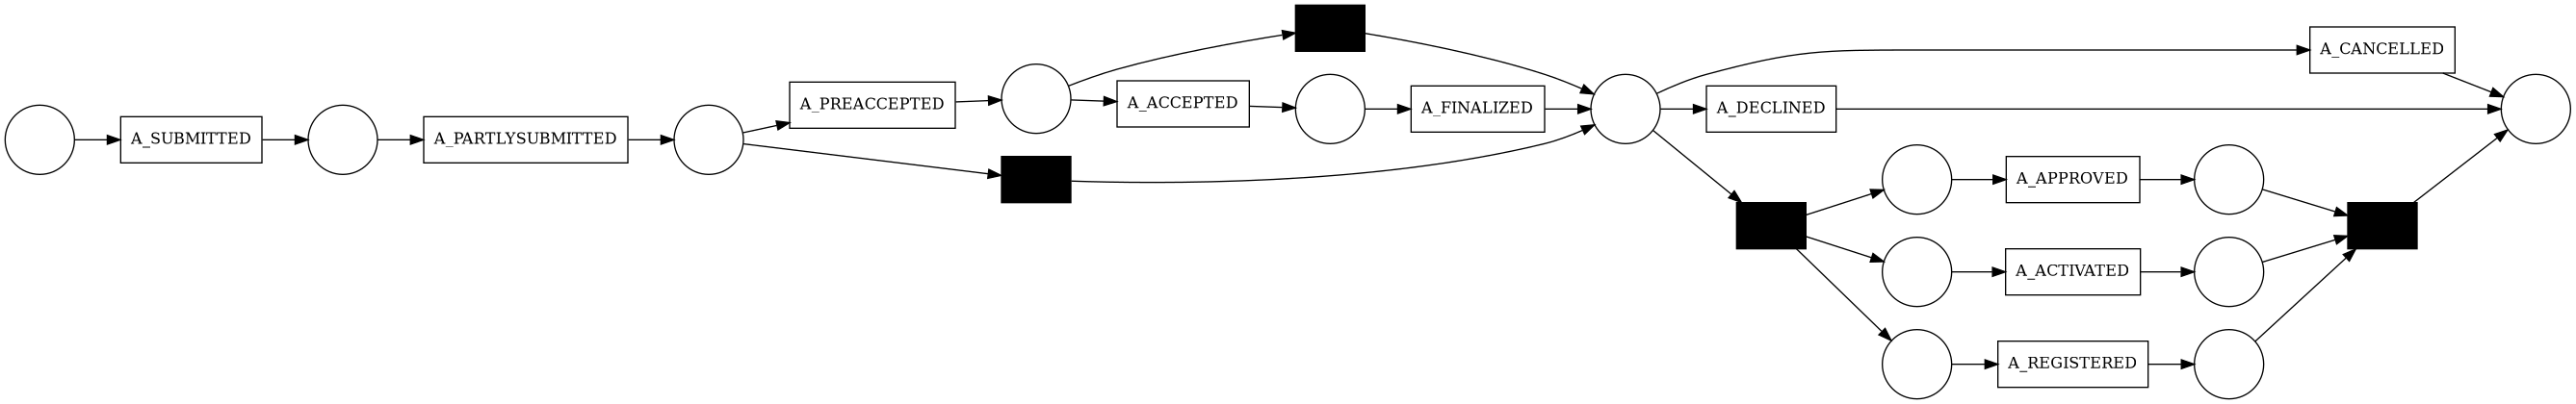

In [48]:
pm4py.view_petri_net(net)

In [49]:
# show complete event log: previous + simulated events

sim_log[sim_log['case:concept:name'] == '206327']

,case:concept:name,concept:name,org:resource,start:timestamp,time:timestamp,case:AMOUNT_REQ
0,206327,A_SUBMITTED,112,2012-02-03 17:23:41.949000+00:00,2012-02-03 17:23:41.949000+00:00,6000
1,206327,A_PARTLYSUBMITTED,112,2012-02-03 17:23:41.949000+00:00,2012-02-03 17:23:42.504000+00:00,6000
2,206327,A_PREACCEPTED,11009,2012-02-03 17:23:42.504000+00:00,2012-02-05 13:14:42.504000+00:00,6000
339,206327,A_ACCEPTED,11009,2012-02-05 13:14:42.504000+00:00,2012-02-05 14:24:42.504000+00:00,6000
355,206327,A_FINALIZED,10881,2012-02-05 14:24:42.504000+00:00,2012-02-05 14:27:42.504000+00:00,6000
356,206327,A_DECLINED,112,2012-02-05 14:27:42.504000+00:00,2012-02-14 10:05:42.504000+00:00,6000


In [50]:
# show simulated events for case "6"

sim_log[sim_log['case:concept:name'] == "6"]

,case:concept:name,concept:name,org:resource,start:timestamp,time:timestamp,case:AMOUNT_REQ
